<a href="https://colab.research.google.com/github/3B232056/2026_DL_hws/blob/main/hw3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#讀入基本套件

In [301]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [302]:
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense,Input
from tensorflow.keras.optimizers import SGD

In [303]:
from tensorflow.keras.datasets import fashion_mnist #一般手寫辨識資料

# 資料預處理


#載入資料

In [304]:
(x_train_image, y_train_label), (x_test_image, y_test_label) = fashion_mnist.load_data()

print("訓練資料筆數:", len(x_train_image))
print("測試資料筆數:", len(x_test_image))

print("x_train:", x_train_image.shape)
print("y_train:", y_train_label.shape)

print("x_test:", x_test_image.shape)
print("y_test:", y_test_label.shape)

訓練資料筆數: 60000
測試資料筆數: 10000
x_train: (60000, 28, 28)
y_train: (60000,)
x_test: (10000, 28, 28)
y_test: (10000,)


In [305]:
label_dict = {
    0: "T-shirt/top",
    1: "Trouser",
    2: "Pullover",
    3: "Dress",
    4: "Coat",
    5: "Sandal",
    6: "Shirt",
    7: "Sneaker",
    8: "Bag",
    9: "Ankle boot"
}

#訓練資料圖片

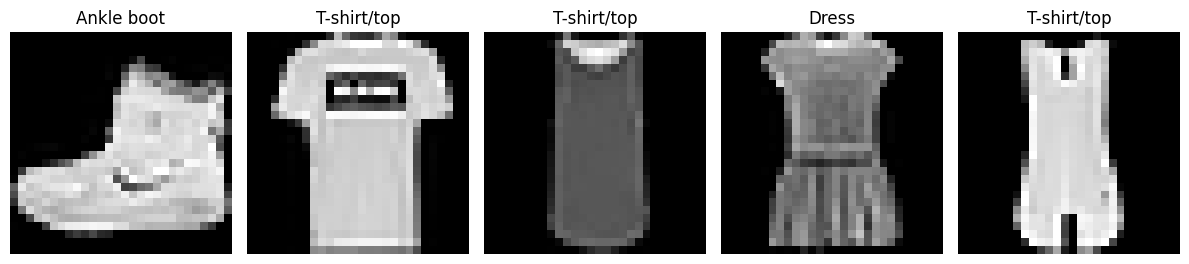

In [306]:
plt.figure(figsize=(12,6))

for i in range(5):
    plt.subplot(2,5,i+1)
    plt.imshow(x_train_image[i], cmap='gray')
    plt.title(label_dict[y_train_label[i]])
    plt.axis('off')

plt.tight_layout()
plt.show()

In [307]:
x_train =x_train_image.reshape(60000, 784).astype('float32')
x_test = x_test_image.reshape(10000, 784).astype('float32')

In [308]:
x_train_normalize = x_train / 255
x_test_normalize = x_test / 255

In [309]:
y_train_OneHot = to_categorical(y_train_label)
y_test_OneHot = to_categorical(y_test_label)

In [310]:
print(x_train_normalize.shape)
print(x_test_normalize.shape)

print(y_train_OneHot.shape)
print(y_test_OneHot.shape)

(60000, 784)
(10000, 784)
(60000, 10)
(10000, 10)


# 建立神經網路模型

In [311]:
from keras.layers import Dropout

In [312]:
model = Sequential()

將「輸入層」與「隱藏層1」加入模型



In [313]:
model.add(Dense(units=1000,
        input_dim=784,
        kernel_initializer='normal',
        activation='relu'
))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [314]:
model.add(Dropout(0.3))

將「隱藏層2」加入模型

In [315]:
model.add(Dense(units=1000,
        kernel_initializer='normal',
        activation='relu'
))

In [316]:
model.add(Dropout(0.3))

將「輸出層」加入模型

In [317]:
model.add(Dense(units=10,
        kernel_initializer='normal',
        activation='softmax'))

In [318]:
print(model.summary())

Model: "sequential_14"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_43 (Dense)                │ (None, 1000)           │       785,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_29 (Dropout)            │ (None, 1000)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_44 (Dense)                │ (None, 1000)           │     1,001,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_30 (Dropout)            │ (None, 1000)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_45 (Dense)                │ (None, 10)             │        10,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,796,010 (6.85 MB)

 Trainable params: 1,796,010 (6.85 MB)

 Non-trainable params: 0 (0.00 B)

None


#每層參數
第一層:784×1000+1000=785,000

第二層:1000×1000+1000=1,001,000

輸出層:1000×10+10=10010

總參數:785,000+1,001,000+10,010=1,796,010

# 訓練神經網路模型

In [319]:
model.compile(loss='categorical_crossentropy',
              optimizer='adam', metrics=['accuracy'])

**驗證(validation)用資料**

從訓練資料當中切出20%作為驗證(validation)用資料
全部訓練資料70000筆資料(手寫數字圖片)當中，其中60000張作為訓練資料，
10000張作為測試資料。60000×0.2=12000筆當作驗證資料，故真正訓練資料只剩48000筆。

**批次大小(batch_size)**

每一訓練回合(epoch)，設定每一批次輸入128筆資料(手寫數字圖片)，所以，每一epoch，有48000/128=375批次。
每一批次輸入128筆資料(手寫數字圖片)，所以：**神經網路輸入資料的形狀為(128, 784)**
**第一隱藏層輸出資料的形狀為(128, 1000)，第二隱藏層輸出資料的形狀為(128, 1000)，輸出層輸出資料的形狀為(128, 10)。**

In [320]:
train_history = model.fit(x=x_train_normalize,
              y=y_train_OneHot,
              validation_split=0.2,
              epochs=20,
              batch_size=128,
              verbose=2)

Epoch 1/20
375/375 - 5s - 12ms/step - accuracy: 0.8066 - loss: 0.5438 - val_accuracy: 0.8522 - val_loss: 0.3946
Epoch 2/20
375/375 - 1s - 4ms/step - accuracy: 0.8533 - loss: 0.4024 - val_accuracy: 0.8674 - val_loss: 0.3632
Epoch 3/20
375/375 - 2s - 4ms/step - accuracy: 0.8648 - loss: 0.3697 - val_accuracy: 0.8698 - val_loss: 0.3524
Epoch 4/20
375/375 - 2s - 7ms/step - accuracy: 0.8714 - loss: 0.3458 - val_accuracy: 0.8727 - val_loss: 0.3544
Epoch 5/20
375/375 - 1s - 4ms/step - accuracy: 0.8763 - loss: 0.3298 - val_accuracy: 0.8796 - val_loss: 0.3290
Epoch 6/20
375/375 - 1s - 4ms/step - accuracy: 0.8806 - loss: 0.3190 - val_accuracy: 0.8760 - val_loss: 0.3395
Epoch 7/20
375/375 - 1s - 4ms/step - accuracy: 0.8861 - loss: 0.3059 - val_accuracy: 0.8733 - val_loss: 0.3356
Epoch 8/20
375/375 - 1s - 4ms/step - accuracy: 0.8900 - loss: 0.2987 - val_accuracy: 0.8789 - val_loss: 0.3454
Epoch 9/20
375/375 - 1s - 4ms/step - accuracy: 0.8910 - loss: 0.2899 - val_accuracy: 0.8870 - val_loss: 0.3116


# 以折線圖顯示訓練過程的loss & accuracy

In [321]:
def show_train_history(train_history,train,validation):
    plt.plot(train_history.history[train])
    plt.plot(train_history.history[validation])
    plt.title('Train History')
    plt.ylabel(train)
    plt.xlabel('Epoch')
    plt.legend(['train', 'validation'], loc='upper left')
    plt.show()

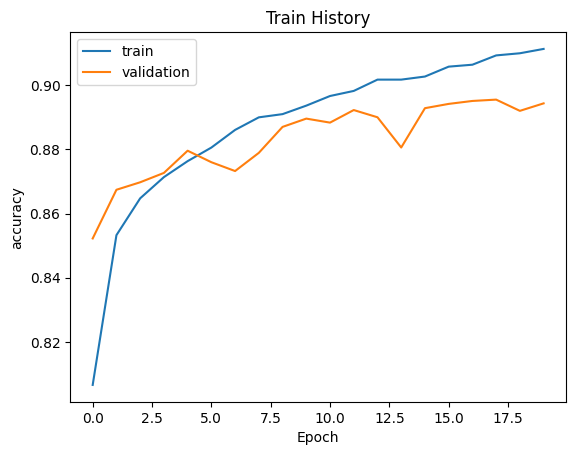

In [322]:
show_train_history(train_history,'accuracy','val_accuracy')

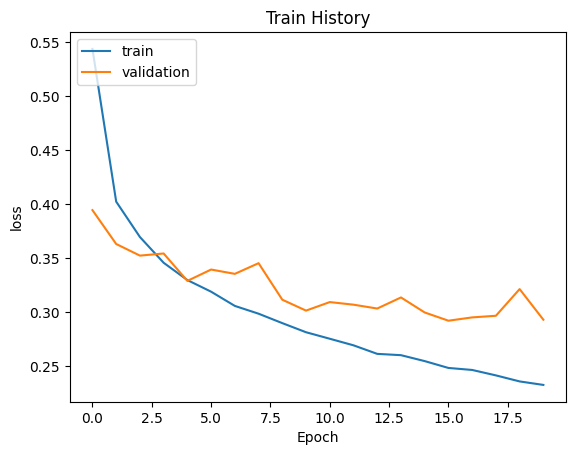

In [323]:
show_train_history(train_history,'loss','val_loss')

#評估模型準確率

In [324]:
scores = model.evaluate(x_test_normalize,y_test_OneHot)

print("Loss =", scores[0])
print("正確率 =", scores[1])

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8892 - loss: 0.3172
Loss = 0.3171513080596924
正確率 = 0.88919997215271


#進行預測

In [325]:
prediction=model.predict(x_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


In [326]:
prediction.shape

(10000, 10)

In [327]:
prediction[456]

array([0., 0., 0., 0., 0., 0., 0., 0., 0., 1.], dtype=float32)

In [328]:
predicted_lable = np.argmax(prediction[456])
predicted_lable

np.int64(9)

神經網路預測是： Ankle boot
實際是： Ankle boot


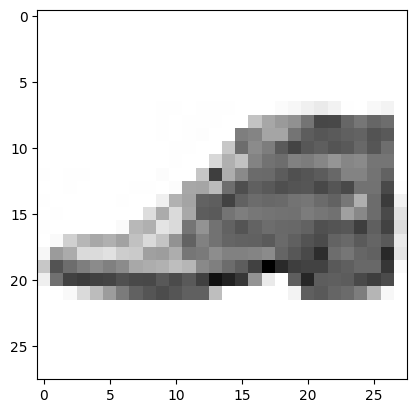

In [329]:
print('神經網路預測是：', label_dict[predicted_lable])
print('實際是：',  label_dict[y_test_label[456]])
plt.imshow(x_test[456].reshape(28,28), cmap='Greys');  # 測試圖片需reshape為原來28x28

In [330]:
def plot_images_labels_prediction(images,labels,prediction,label_dict, idx,num=10):
    fig = plt.gcf()
    fig.set_size_inches(12, 14)
    if num>25: num=25
    for i in range(0, num):
        ax=plt.subplot(5,5, 1+i)
        ax.imshow(images[idx], cmap='binary')
        title= "label=" +str(label_dict[labels[idx]])
        if len(prediction)>0:
            title+=", predict=" +str(np.argmax(prediction[idx]))

        ax.set_title(title,fontsize=10)
        ax.set_xticks([]);ax.set_yticks([])
        idx+=1
    plt.show()

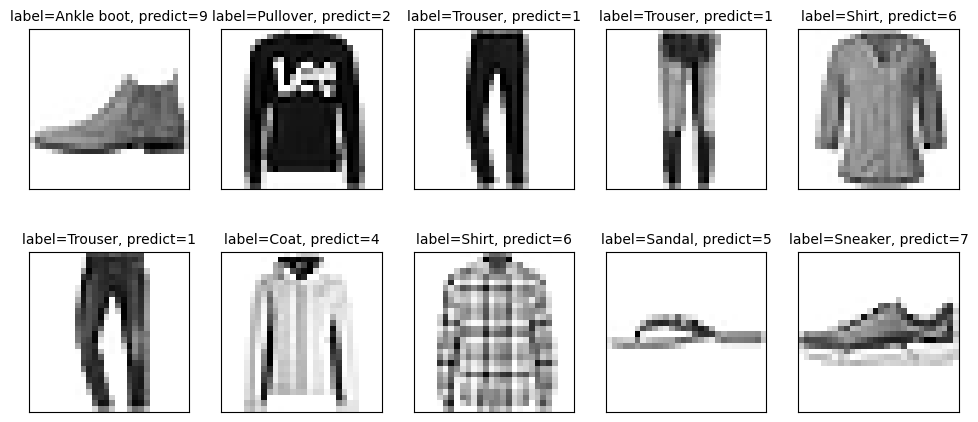

In [331]:
plot_images_labels_prediction(x_test_image, y_test_label, prediction, label_dict, idx=0, num=10)

#confusion matrix (混淆矩陣)

預測結果與真實結果相同或不同的情形

In [332]:
# 將10000個預測結果一一轉換為
predicted_labels = np.argmax(prediction, axis=1)

# Now use predicted_labels in crosstab
pd.crosstab(y_test_label, predicted_labels, rownames=['label'], colnames=['predict'])

predict,0,1,2,3,4,5,6,7,8,9
label,,,,,,,,,,
0,865,6,12,8,10,0,91,1,7,0
1,2,984,2,6,4,0,1,0,1,0
2,16,0,767,7,159,0,49,0,1,1
3,29,30,15,840,62,0,20,0,4,0
4,0,0,71,10,901,0,17,0,1,0
5,1,0,0,0,0,937,0,16,1,45
6,133,4,78,17,156,0,595,0,17,0
7,0,0,0,0,0,14,0,892,0,94
8,5,0,2,1,6,1,2,3,979,1


In [333]:
# 每一筆測試資料的真實結果標籤(label)與預測結果標籤(predict)的表格(df)

df = pd.DataFrame({'label': y_test_label, 'predict': predicted_labels})
df[:10] # 表格前10筆測試資料

,label,predict
0,9,9
1,2,2
2,1,1
3,1,1
4,6,6
5,1,1
6,4,4
7,6,6
8,5,5
9,7,7


In [334]:
df[(df.label==6)&(df.predict==8)]  # 真實標籤為6，卻預測為8

,label,predict
1645,6,8
2367,6,8
2732,6,8
2910,6,8
3663,6,8
3741,6,8
3881,6,8
4505,6,8
4642,6,8
5065,6,8


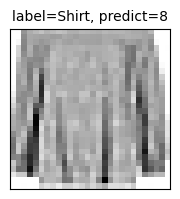

In [335]:
plot_images_labels_prediction(x_test_image, y_test_label, prediction, label_dict, idx=2367, num=1)

#8是"Bag"，所以預測錯誤，實際應為6"Shirt"

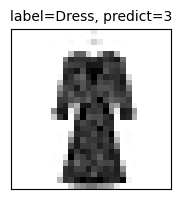

In [336]:
plot_images_labels_prediction(x_test_image, y_test_label, prediction, label_dict, idx=266, num=1)

#3是"Dress",，所以預測正確

#更酷炫的互動呈現

In [337]:
from ipywidgets import interact_manual

In [338]:
def test(測試編號):
  plt.imshow(x_test[測試編號].reshape(28,28), cmap='Greys') #要將拉平的維度弄回 (28, 28)
  pred_class = predicted_labels[測試編號]
  actual_class = y_test_label[測試編號]
  print('神經網路判斷為:', label_dict[pred_class], f'({pred_class})')
  print('實際答案為:', label_dict[actual_class], f'({actual_class})')

In [339]:
interact_manual(test, 測試編號=(0, 9999));

interactive(children=(IntSlider(value=4999, description='測試編號', max=9999), Button(description='Run Interact', …

#儲存完整模型

把神經網路的架構和訓練好的參數都存起來, 以供日後使用!

In [343]:
#儲存 model
from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [344]:
%cd '/content/drive/My Drive/Colab Notebooks'

/content/drive/My Drive/Colab Notebooks


In [345]:
model.save('my_dnn_model_hw3.keras')